# Batch evaluation and analysis

## Goal
Evaluate several transcript–summary pairs concurrently, compare their independent scores, and inspect recurring problems before improving the Zoom summary prompt. All bundled inputs are explicitly fictional software fixtures.

This notebook makes real, billable API calls. The default includes three short meetings and two core scores plus diagnostics per meeting. Scores are model judgments rather than fixed expected values or acceptance decisions.

Saved output paths use `<PROJECT_ROOT>` in place of the local project folder.

## Setup
Install from the project root with `.venv/bin/python -m pip install -e '.[dev,notebooks]'` and run `.venv/bin/jupyter lab notebooks`. Use the project's `.env` for credentials. The examples assume the supported model ID is `gpt-6-luna`; change it for your endpoint if needed.

In [1]:
from pathlib import Path
from dotenv import load_dotenv

# Works when Jupyter starts from the project root or the notebooks folder.
ROOT = next(path for path in [Path.cwd(), Path.cwd().parent] if (path / "pyproject.toml").exists())
load_dotenv(ROOT / ".env", override=False)
print("Project:", ROOT)

Project: <PROJECT_ROOT>


## Steps
### 1. Choose input folders and concurrency
Files match by case-sensitive stem, so `meeting_001.txt` can pair with `meeting_001.md`. Use two flat folders containing `.txt` or `.md` files. A shared limit bounds actual in-flight judge requests, including calls inside individual metrics. Set `MAX_CONCURRENCY = 1` for sequential debugging.

In [2]:
from meeting_eval import MeetingSummaryEvaluator

TRANSCRIPT_DIR = ROOT / "examples/data/transcripts"
SUMMARY_DIR = ROOT / "examples/data/summaries"
OUTPUT_DIR = ROOT / "results/notebook"
MODEL = "gpt-6-luna"
MAX_CONCURRENCY = 4

print("Transcripts:", sorted(path.name for path in TRANSCRIPT_DIR.iterdir() if path.suffix.lower() in {".txt", ".md"}))
print("Summaries:", sorted(path.name for path in SUMMARY_DIR.iterdir() if path.suffix.lower() in {".txt", ".md"}))
evaluator = MeetingSummaryEvaluator(model=MODEL, max_concurrency=MAX_CONCURRENCY, env_file=ROOT / ".env")

Warning: DeepEval is configured for read only environment. Test runs will not be written to disk.

Transcripts: ['meeting_001.txt', 'meeting_002.txt', 'meeting_003.txt']
Summaries: ['meeting_001.md', 'meeting_002.md', 'meeting_003.md']


### 2. Run the batch
Missing pairs, invalid files, and failed evaluations stay associated with their meeting IDs. Successful meetings remain available if another meeting fails. Each output directory contains the detailed JSON, a score-comparison CSV, and a local HTML report.

In [3]:
batch = await evaluator.aevaluate_batch(
    transcript_dir=TRANSCRIPT_DIR,
    summary_dir=SUMMARY_DIR,
    output_dir=OUTPUT_DIR,
)
print("Meetings:", len(batch.results))
print("Saved run:", batch.output_dir)

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<PROJECT_ROOT>/.venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')


Meetings: 3
Saved run: <PROJECT_ROOT>/results/notebook/20261028T132433Z-f3067d5a


### 3. Compare the result table
Missing scores remain missing, rather than being treated as zero. Execution status and review flags provide essential context for numerical comparisons.

In [4]:
import pandas as pd
from IPython.display import display

comparison = batch.to_dataframe()
display(comparison)

,meeting_id,execution_status,review_required,diagnostics_status,review_reasons,high_severity_findings,finding_count,errors,coverage_score,coverage_status,faithfulness_score,faithfulness_status
0,meeting_001,completed,True,completed,Faithfulness found contradicted or ambiguously...,0,0,,1.0,completed,0.928571,completed
1,meeting_002,completed,True,completed,Faithfulness found contradicted or ambiguously...,1,3,,0.3,completed,0.750000,completed
2,meeting_003,completed,True,completed,Faithfulness found contradicted or ambiguously...,4,5,,0.0,completed,0.142857,completed


### 4. Compare the two scores visually
Both axes share the 0–1 range, but the scores measure different things. Faithfulness is a supported-claim ratio; coverage is a rubric judgment about important information. Do not average them. The fictional examples are designed to contrast faithful, incomplete, and materially distorted summaries.

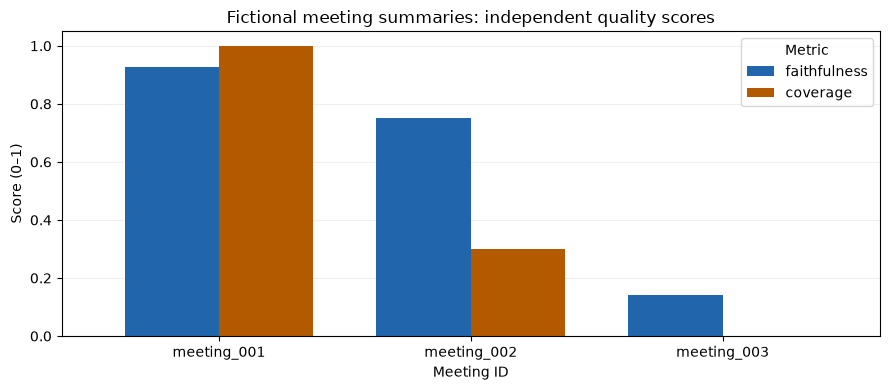

In [5]:
import matplotlib.pyplot as plt

score_table = pd.DataFrame(
    {result.meeting_id: {name: metric.score for name, metric in result.metrics.items()}
     for result in batch.results}
).T.sort_index()
if score_table.notna().any().any():
    ax = score_table.plot.bar(
        figsize=(9, 4), color=["#2166AC", "#B35900"], rot=0, width=0.75,
    )
    ax.set(title="Fictional meeting summaries: independent quality scores", xlabel="Meeting ID", ylabel="Score (0–1)", ylim=(0, 1.05))
    ax.legend(title="Metric", loc="upper right")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print("No completed metric scores to plot. Inspect execution errors below.")

### 5. Find recurring evaluation issues
Counts describe returned findings, not a prevalence estimate: the sample is tiny, synthetic, and intentionally includes failures. A high count can reflect multiple findings in one meeting. Read the evidence before treating a suggested prompt change as established.

In [6]:
finding_rows = [
    {
        "meeting_id": result.meeting_id,
        "kind": finding.kind,
        "severity": finding.severity,
        "section": finding.section,
        "description": finding.description,
        "verified_quotes": sum(evidence.verified for evidence in finding.evidence),
        "suggested_prompt_change": finding.suggested_prompt_change,
    }
    for result in batch.results
    for finding in result.findings
]
findings = pd.DataFrame(finding_rows)
if not findings.empty:
    recurring = findings.groupby(["kind", "severity"], dropna=False).size().rename("findings").reset_index().sort_values("findings", ascending=False)
    display(recurring)
    display(findings[["meeting_id", "severity", "description", "suggested_prompt_change"]])
else:
    print("No diagnostic findings were returned. Check execution status before interpreting this.")

,kind,severity,findings
4,missing_topic,medium,3
0,contradiction,high,1
1,fidelity_attribution,high,1
2,material_distortion,high,1
3,missing_topic,high,1
5,product_claim,high,1


,meeting_id,severity,description,suggested_prompt_change
0,meeting_002,high,The summary omits the meeting’s central develo...,Require the summary to retain the main market ...
1,meeting_002,medium,The summary omits the explicit sales follow-up...,Preserve explicitly discussed sales discovery ...
2,meeting_002,medium,The summary omits the explicit concentration-d...,"Retain concrete, explicitly discussed advisor ..."
3,meeting_003,high,The summary reverses the spread move and chang...,"Preserve the direction, unit, and timeframe of..."
4,meeting_003,high,The summary reverses Fidelity's stated cautiou...,Attribute views to the actual speaker and pres...
5,meeting_003,high,The summary invents a fund recommendation and ...,Include product recommendations or guarantees ...
6,meeting_003,high,The summary reverses the substantive Q&A: the ...,Capture both the question and answer faithfull...
7,meeting_003,medium,The summary omits the explicit advisor talking...,Retain explicitly discussed sales guidance and...


### 6. Inspect the source evidence for a flagged meeting
Change `SELECTED_MEETING` to follow a different row. A quote's verified flag checks that its exact text was uniquely located; missing or repeated quotations remain unverified without source lines. Semantic support still needs review. Model findings should not be described as human-confirmed failures.

In [7]:
SELECTED_MEETING = "meeting_003"
selected = next(result for result in batch.results if result.meeting_id == SELECTED_MEETING)
print("Execution:", selected.execution_status)
print("Review reasons:", selected.review_reasons)
for finding in selected.findings:
    print(f"[{finding.severity}] {finding.description}")
    for evidence in finding.evidence:
        print(f"  {evidence.source}, line {evidence.line_start}, verified={evidence.verified}: {evidence.quote}")
for result in batch.results:
    if result.errors:
        print(result.meeting_id, "evaluation errors:", result.errors)

Execution: completed
Review reasons: ['Faithfulness found contradicted or ambiguously supported claims.', 'Material judge finding requires human review.']
[high] The summary reverses the spread move and changes its timeframe and meaning: the source says spreads widened 15 basis points during the week, not narrowed during the year or produced a 15% return. It also says all bond prices rose, contrary to the source's explicit qualification.
  summary, line 4, verified=True: Credit spreads narrowed by 15 basis points this year, producing a 15% return.
  summary, line 11, verified=True: All bond prices rose because spreads narrowed.
  transcript, line 4, verified=True: Investment-grade credit spreads widened by 15 basis points during the scenario's week.
  transcript, line 5, verified=True: This is not a statement that all bond prices rose.
  transcript, line 7, verified=True: The 15-basis-point move refers to the week, not the year, and is not a 15-percent return.
[high] The summary revers

### 7. Export the analysis table
The evaluation artifacts have already been saved. This creates an additional Pandas analysis export next to them so you can edit this notebook's comparison without changing the detailed JSON.

In [8]:
run_dir = Path(batch.output_dir)
comparison.to_csv(run_dir / "notebook_comparison.csv", index=False)
if not findings.empty:
    findings.to_csv(run_dir / "notebook_findings.csv", index=False)
print("Analysis exports:", run_dir)
print("Open the HTML report in this run directory to inspect the complete results.")

Analysis exports: <PROJECT_ROOT>/results/notebook/20261028T132433Z-f3067d5a
Open the HTML report in this run directory to inspect the complete results.


## Checks
Use a fixed set of meetings, model, and rubric version for prompt comparisons. Inspect incomplete evaluations independently from summary problems. Lower concurrency may help when provider token-per-minute limits cause retries.

In [9]:
assert len({result.meeting_id for result in batch.results}) == len(batch.results)
assert all(metric.score is None or 0 <= metric.score <= 1
           for result in batch.results for metric in result.metrics.values())
print("Execution statuses:", pd.Series([result.execution_status for result in batch.results]).value_counts().to_dict())
print("Meetings requiring review:", [result.meeting_id for result in batch.results if result.review_required])

Execution statuses: {'completed': 3}
Meetings requiring review: ['meeting_001', 'meeting_002', 'meeting_003']


## Next steps
Replace the example folders with your meeting files. Look for repeated omissions or attribution problems, make one focused change to the Zoom prompt, and rerun the same meeting set. Read both improvements and regressions; there is no weighted score that can hide a material distortion.

Before operational use, compare findings against independent subject-matter review of real summaries. These synthetic fixtures exercise the pipeline and demonstrate failure modes; they do not calibrate judge reliability.